# DAR ES SALAAM INSTITUTE OF TECHNOLOGY

## DIGITAL SIGNAL PROCESSING LABORATORY

### WEEK 2 – LAB 1A
### Sampling, Aliasing and Quantization

**Module Code:** COU 07506

**Student Name:** Gwamaka A Mwakabuta

**Registration Number:** 240242462281

**Academic Year:** 2026/2027

**Unit:** Unit 1 – Signals, Sampling and Systems

In [1]:
# ==========================================
# WEEK 2 - LAB 1A
# Required DSP Libraries
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

print("Week 2 DSP environment ready!")

Matplotlib is building the font cache; this may take a moment.


Week 2 DSP environment ready!


## Pre-lab Preparation

### Question 1: Aliasing

A 7 kHz tone is sampled at 10 kHz.

Given:
- Original frequency = 7,000 Hz
- Sampling frequency = 10,000 Hz

Nyquist frequency:

fN = fs / 2
fN = 10,000 / 2
fN = 5,000 Hz

Since 7,000 Hz is greater than 5,000 Hz,
aliasing occurs.

Alias frequency:

f_alias = |7,000 - 10,000|

f_alias = 3,000 Hz

**Answer: 3 kHz**

### Question 2: Quantization

Given:
- Number of bits B = 8
- Full-scale range = ±1 V

Quantization step size:

Δ = 2Xm / 2^B

Δ = 2 / 256

Δ = 0.0078125 V

Theoretical SQNR:

SQNR = 6.02B + 1.76

SQNR = 6.02(8) + 1.76

SQNR = 49.92 dB

**Answer:**
- Quantization step size = 0.0078125 V
- Theoretical SQNR = 49.92 dB

In [2]:
# ==========================================
# WEEK 2 - LAB 1A
# Import Required Libraries
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

print("Week 2 DSP environment ready!")

Week 2 DSP environment ready!


## Task 2.1 – Aliasing of a Sinusoid

### Objective
To demonstrate aliasing using a 7 Hz cosine signal
sampled at different sampling frequencies.

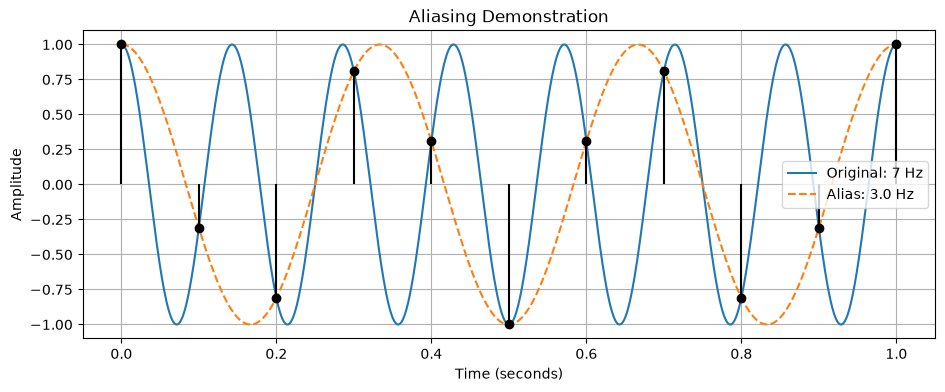

Original frequency: 7.0 Hz
Sampling frequency: 10.0 Hz
Nyquist frequency: 5.0 Hz
Alias frequency: 3.0 Hz


In [3]:
# ==========================================
# TASK 2.1 - ALIASING OF A SINUSOID
# ==========================================

# Original signal frequency
f0 = 7.0

# Sampling frequency
fs = 10.0

# Generate continuous-time representation
t = np.linspace(0, 1, 2000)

# Generate discrete sampling positions
n = np.arange(0, int(fs) + 1)
tn = n / fs

# Calculate alias frequency
k = round(f0 / fs)
f_alias = abs(f0 - k * fs)

# Generate original signal
x_original = np.cos(2 * np.pi * f0 * t)

# Generate alias signal
x_alias = np.cos(2 * np.pi * f_alias * t)

# Plot original and alias signals
plt.figure(figsize=(11, 4))

plt.plot(t, x_original, label="Original: 7 Hz")

plt.plot(t, x_alias, "--",
         label=f"Alias: {f_alias} Hz")

# Plot sampled signal
plt.stem(
    tn,
    np.cos(2 * np.pi * f0 * tn),
    linefmt="k-",
    markerfmt="ko",
    basefmt=" "
)

plt.title("Aliasing Demonstration")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)

plt.show()

# Display numerical results
print("Original frequency:", f0, "Hz")
print("Sampling frequency:", fs, "Hz")
print("Nyquist frequency:", fs / 2, "Hz")
print("Alias frequency:", f_alias, "Hz")

In [4]:
# ==========================================
# TASK 2.1 - SAMPLING FREQUENCY COMPARISON
# ==========================================

# Original signal frequency
f0 = 7.0

# Different sampling frequencies
sampling_rates = [10, 12, 14, 20]

print("SAMPLING AND ALIASING COMPARISON")
print("-" * 55)
print(f"{'fs (Hz)':<12}{'Nyquist (Hz)':<18}{'Alias (Hz)':<12}")
print("-" * 55)

for fs_test in sampling_rates:

    # Calculate Nyquist frequency
    nyquist = fs_test / 2

    # Calculate folded alias frequency
    remainder = f0 % fs_test
    f_alias = min(remainder, fs_test - remainder)

    print(f"{fs_test:<12}{nyquist:<18.1f}{f_alias:<12.1f}")

SAMPLING AND ALIASING COMPARISON
-------------------------------------------------------
fs (Hz)     Nyquist (Hz)      Alias (Hz)  
-------------------------------------------------------
10          5.0               3.0         
12          6.0               5.0         
14          7.0               7.0         
20          10.0              7.0         


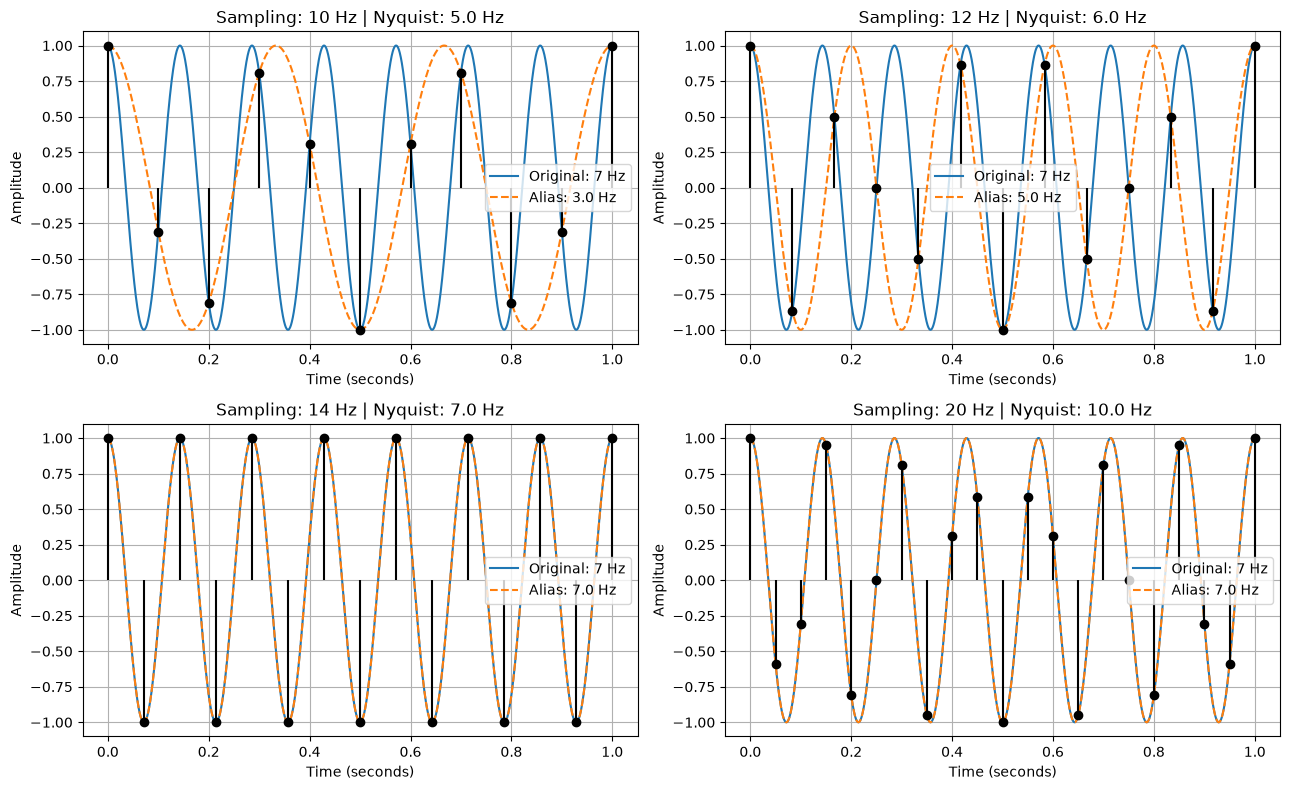

In [5]:
# ==========================================
# TASK 2.1 - COMPARISON GRAPHS
# ==========================================

f0 = 7.0
sampling_rates = [10, 12, 14, 20]

# Dense time axis
t = np.linspace(0, 1, 2000)

# Original signal
x_original = np.cos(2 * np.pi * f0 * t)

# Create four plotting areas
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

axes = axes.flatten()

for ax, fs_test in zip(axes, sampling_rates):

    # Generate sampling positions
    n_test = np.arange(0, int(fs_test) + 1)
    tn_test = n_test / fs_test

    # Calculate alias frequency
    remainder = f0 % fs_test
    f_alias = min(remainder, fs_test - remainder)

    # Generate alias signal
    x_alias = np.cos(2 * np.pi * f_alias * t)

    # Plot original signal
    ax.plot(t, x_original, label="Original: 7 Hz")

    # Plot alias signal
    ax.plot(t, x_alias, "--",
            label=f"Alias: {f_alias:.1f} Hz")

    # Plot sampled points
    ax.stem(
        tn_test,
        np.cos(2 * np.pi * f0 * tn_test),
        linefmt="k-",
        markerfmt="ko",
        basefmt=" "
    )

    ax.set_title(
        f"Sampling: {fs_test} Hz | "
        f"Nyquist: {fs_test/2} Hz"
    )

    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Amplitude")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

### Task 2.1 – Experimental Observations

The experiment investigated a 7 Hz cosine signal at
sampling frequencies of 10 Hz, 12 Hz, 14 Hz and 20 Hz.

The following observations were obtained:

1. At 10 Hz, the signal produced an alias frequency
   of 3 Hz.

2. At 12 Hz, the signal produced an alias frequency
   of 5 Hz.

3. At 14 Hz, the signal was sampled exactly at the
   Nyquist frequency of 7 Hz.

4. At 20 Hz, the signal frequency of 7 Hz was below
   the Nyquist frequency of 10 Hz.

The experiment demonstrates that insufficient
sampling can cause a signal to be represented by
an incorrect apparent frequency.

The sampling frequency should be greater than twice
the highest frequency component for reliable
reconstruction of a band-limited signal.

## Task 2.2 – Hearing Aliasing

### Comparing Naive Downsampling and Proper Decimation

In [6]:
# ==========================================
# WEEK 2 - TASK 2.2
# HEARING ALIASING
# ==========================================

from pathlib import Path
from IPython.display import Audio, display

# Locate the Week 1 voice recording
possible_paths = [
    Path("../Week-01/my_voice.wav"),
    Path("Week-01/my_voice.wav"),
    Path("my_voice.wav")
]

fname = next(
    (p for p in possible_paths if p.is_file()),
    None
)

if fname is None:
    raise FileNotFoundError(
        "Could not locate my_voice.wav"
    )

# Read the original recording
fs, audio_raw = wavfile.read(str(fname))

# Convert to floating-point values
x_audio = np.asarray(audio_raw, dtype=float)

# Convert stereo to mono
if x_audio.ndim > 1:
    x_audio = x_audio.mean(axis=1)

# Normalize the audio
peak = np.max(np.abs(x_audio))

if peak == 0:
    raise ValueError("Audio recording is silent.")

x_audio = x_audio / peak

# Display recording information
print("Original sampling rate:", fs, "Hz")
print("Original duration:",
      round(len(x_audio) / fs, 2), "seconds")
print("Original samples:", len(x_audio))
print("Recording file:", fname.resolve())

Original sampling rate: 48000 Hz
Original duration: 4.85 seconds
Original samples: 232799
Recording file: C:\Users\Gwamaka Mwakabuta\Desktop\3 year\DSP\COU07506-DSP-Labs\Week-01\my_voice.wav


In [7]:
# ==========================================
# TASK 2.2 - DOWNSAMPLING COMPARISON
# ==========================================

for k in [2, 4, 8]:

    # Method A: Naive downsampling
    naive = x_audio[::k]

    # Method B: Proper decimation with FIR filter
    proper = signal.decimate(
        x_audio,
        k,
        ftype="fir"
    )

    # Calculate new sampling rate
    new_fs = fs // k

    print("\n================================")
    print("Reduction factor:", k)
    print("New sampling rate:", new_fs, "Hz")
    print("================================")

    print("Naive downsampling - No filter")
    display(Audio(naive, rate=new_fs))

    print("Proper decimation - FIR filter")
    display(Audio(proper, rate=new_fs))


Reduction factor: 2
New sampling rate: 24000 Hz
Naive downsampling - No filter


Proper decimation - FIR filter



Reduction factor: 4
New sampling rate: 12000 Hz
Naive downsampling - No filter


Proper decimation - FIR filter



Reduction factor: 8
New sampling rate: 6000 Hz
Naive downsampling - No filter


Proper decimation - FIR filter


### Task 2.2 – Listening Observations

**Reduction factor k = 2:**

Naive version:
[Write your listening observation.]

Proper decimation:
[Write your listening observation.]

**Reduction factor k = 4:**

Naive version:
[Write your listening observation.]

Proper decimation:
[Write your listening observation.]

**Reduction factor k = 8:**

Naive version:
[Write your listening observation.]

Proper decimation:
[Write your listening observation.]

### Discussion

The naive downsampling method removes samples without
first applying a low-pass filter. This can cause aliasing.

Proper decimation applies an anti-aliasing FIR filter
before reducing the sampling rate.

Therefore, proper decimation reduces aliasing, although
some high-frequency information is lost.

## Task 2.3 – A Uniform Quantizer

### Objective

To implement a uniform quantizer, observe the
quantized output and calculate the quantization error.

### Experimental Parameters

- Sampling frequency: 8000 Hz
- Signal frequency: 300 Hz
- Signal amplitude: 0.99 V
- Full-scale range: ±1 V
- Quantization resolution: 3 bits

In [8]:
# ==========================================
# WEEK 2 - TASK 2.3
# IMPLEMENTING A UNIFORM QUANTIZER
# ==========================================

# Step 1: Define the quantization function

def quantize(x, bits, full_scale=1.0):

    # Calculate quantization step size
    delta = 2 * full_scale / 2**bits

    # Map samples to nearest quantization level
    q = np.round(x / delta) * delta

    # Limit output to the valid quantization range
    return np.clip(q, -full_scale, full_scale - delta)


# Step 2: Define experimental parameters

fs = 8000              # Sampling frequency (Hz)
f0 = 300               # Signal frequency (Hz)
bits = 3               # Quantizer resolution
full_scale = 1.0       # Full-scale amplitude (V)

# Step 3: Generate time samples
t = np.arange(0, 0.01, 1/fs)

# Step 4: Generate original sinusoidal signal
x = 0.99 * np.sin(2 * np.pi * f0 * t)

# Step 5: Quantize the original signal
xq = quantize(x, bits, full_scale)

# Step 6: Calculate quantization error
error = x - xq

# Step 7: Calculate quantization step
delta = 2 * full_scale / 2**bits

# Display numerical information
print("Sampling frequency:", fs, "Hz")
print("Signal frequency:", f0, "Hz")
print("Quantizer resolution:", bits, "bits")
print("Number of levels:", 2**bits)
print("Quantization step:", delta, "V")
print("Number of samples:", len(x))

Sampling frequency: 8000 Hz
Signal frequency: 300 Hz
Quantizer resolution: 3 bits
Number of levels: 8
Quantization step: 0.25 V
Number of samples: 80


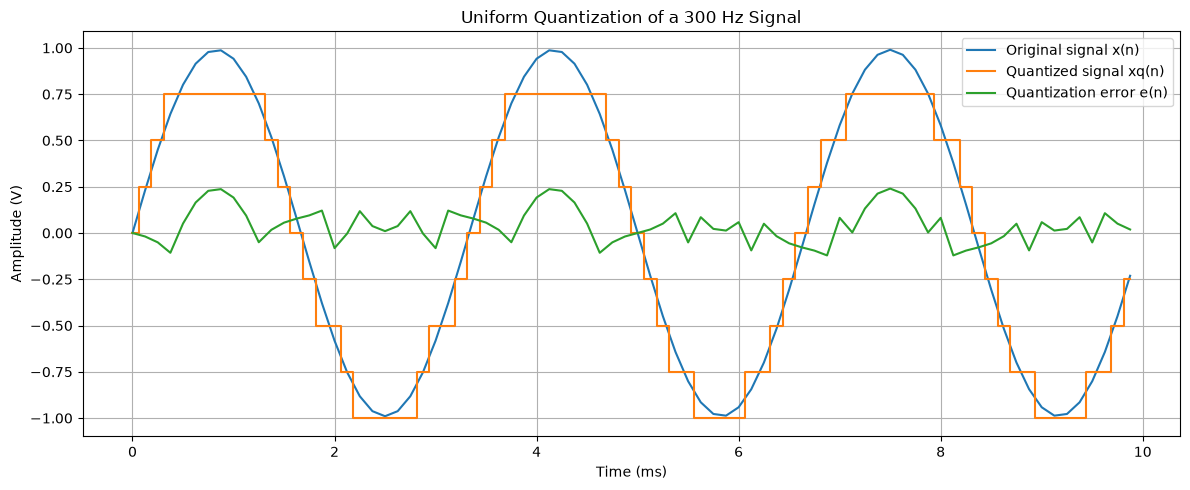

In [9]:
# ==========================================
# TASK 2.3 - SIGNAL VISUALIZATION
# ==========================================

plt.figure(figsize=(12, 5))

# Original signal
plt.plot(
    t * 1e3,
    x,
    label="Original signal x(n)"
)

# Quantized signal
plt.step(
    t * 1e3,
    xq,
    where="mid",
    label="Quantized signal xq(n)"
)

# Quantization error
plt.plot(
    t * 1e3,
    error,
    label="Quantization error e(n)"
)

plt.title("Uniform Quantization of a 300 Hz Signal")
plt.xlabel("Time (ms)")
plt.ylabel("Amplitude (V)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Task 2.3 – Experimental Observations

The experiment implemented a 3-bit uniform quantizer
on a 300 Hz sinusoidal signal.

The quantizer produced eight discrete amplitude levels
with a quantization step size of 0.25 V.

The original sinusoidal signal was converted into a
staircase-like waveform because its amplitudes were
mapped to the nearest available quantization levels.

The quantization error represents the difference
between the original signal and its quantized output.

The experiment demonstrates that quantization
introduces amplitude errors when representing
analogue signals digitally.

## Task 2.4 – Verify the 6 dB-per-bit Rule

### Objective

To calculate measured and theoretical SQNR values
for different quantizer resolutions and compare
their relationship with the number of bits.

In [10]:
# ==========================================
# WEEK 2 - TASK 2.4
# VERIFY THE 6 dB-PER-BIT RULE
# ==========================================

# Quantizer resolutions from 2 to 16 bits
bits = np.arange(2, 17, 2)

# Calculate measured SQNR
measured_sqnr = []

for B in bits:

    # Quantize the original signal
    xq_test = quantize(x, B)

    # Calculate quantization error
    e = x - xq_test

    # Calculate signal power
    signal_power = np.sum(x**2)

    # Calculate quantization noise power
    noise_power = np.sum(e**2)

    # Calculate measured SQNR
    sqnr = 10 * np.log10(signal_power / noise_power)

    measured_sqnr.append(sqnr)


# Calculate theoretical SQNR
theoretical_sqnr = 6.02 * bits + 1.76


# Print the results
print("SQNR COMPARISON")
print("-" * 45)
print(f"{'Bits':<10}{'Measured (dB)':<18}{'Theoretical (dB)'}")
print("-" * 45)

for B, measured, theoretical in zip(
    bits, measured_sqnr, theoretical_sqnr
):
    print(f"{B:<10}{measured:<18.2f}{theoretical:.2f}")

SQNR COMPARISON
---------------------------------------------
Bits      Measured (dB)     Theoretical (dB)
---------------------------------------------
2         9.60              13.80
4         23.58             25.84
6         36.81             37.88
8         48.93             49.92
10        62.81             61.96
12        72.84             74.00
14        88.13             86.04
16        98.91             98.08


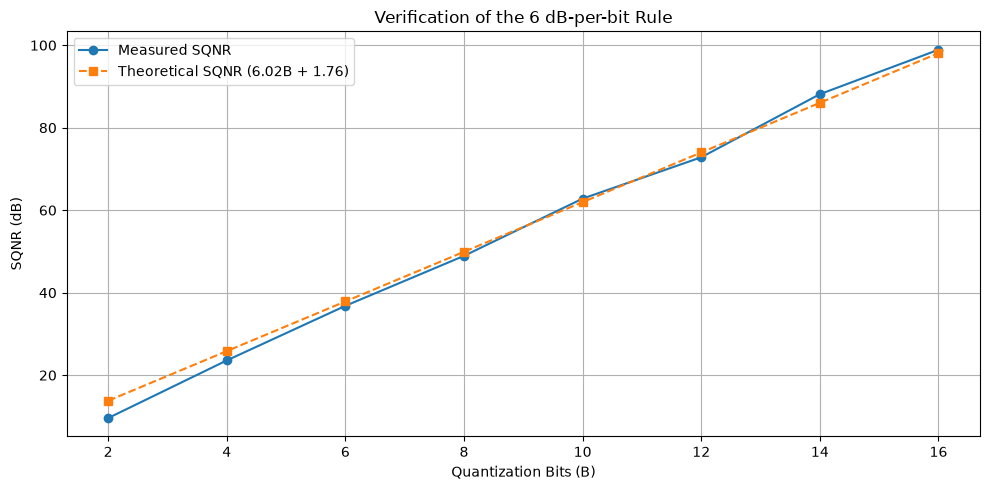

In [11]:
# ==========================================
# TASK 2.4 - SQNR GRAPH
# ==========================================

plt.figure(figsize=(10, 5))

# Measured SQNR
plt.plot(
    bits,
    measured_sqnr,
    "o-",
    label="Measured SQNR"
)

# Theoretical SQNR
plt.plot(
    bits,
    theoretical_sqnr,
    "s--",
    label="Theoretical SQNR (6.02B + 1.76)"
)

plt.title("Verification of the 6 dB-per-bit Rule")
plt.xlabel("Quantization Bits (B)")
plt.ylabel("SQNR (dB)")

plt.xticks(bits)
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Task 2.4 – Experimental Discussion

The experiment investigated the relationship between
quantization resolution and Signal-to-Quantization-Noise
Ratio (SQNR).

The results demonstrate that SQNR generally increases
as the number of quantization bits increases.

The theoretical relationship predicts an improvement
of approximately 6.02 dB for every additional bit.

Since the experiment increased the resolution by two
bits at a time, the theoretical improvement was
approximately 12.04 dB per measurement interval.

The average measured improvement was approximately
6.38 dB per bit.

The measured results approximately agree with the
theoretical 6 dB-per-bit rule. Small differences occur
because of finite signal samples and the characteristics
of the quantization error.

## Task 2.5 – Quantize Your Voice

### Objective

To quantize the recorded voice signal using 4-bit,
8-bit and 12-bit resolutions, listen to each version
and calculate the corresponding SQNR values.

In [12]:
# ==========================================
# WEEK 2 - TASK 2.5
# QUANTIZATION OF MY VOICE
# ==========================================

from pathlib import Path

# Locate the Week 1 recording
voice_path = Path("../Week-01/my_voice.wav")

if not voice_path.exists():
    raise FileNotFoundError("Voice recording not found.")

# Load the original recording
voice_fs, voice_raw = wavfile.read(str(voice_path))

# Convert to floating-point
voice = np.asarray(voice_raw, dtype=float)

# Convert stereo to mono
if voice.ndim > 1:
    voice = voice.mean(axis=1)

# Normalize audio
peak = np.max(np.abs(voice))

if peak == 0:
    raise ValueError("Recording is silent.")

voice = voice / peak

print("Original sampling rate:", voice_fs, "Hz")
print("Recording duration:",
      round(len(voice) / voice_fs, 2), "seconds")
print("Number of samples:", len(voice))

Original sampling rate: 48000 Hz
Recording duration: 4.85 seconds
Number of samples: 232799


In [13]:
# ==========================================
# TASK 2.5 - QUANTIZATION AND SQNR
# ==========================================

bits_to_test = [4, 8, 12]

voice_quantized = {}
voice_sqnr = {}

print("VOICE QUANTIZATION RESULTS")
print("-" * 45)
print(f"{'Bits':<10}{'Levels':<12}{'SQNR (dB)'}")
print("-" * 45)

for B in bits_to_test:

    # Quantize voice recording
    xq_voice = quantize(voice, B, full_scale=1.0)

    # Calculate quantization error
    e_voice = voice - xq_voice

    # Calculate signal power
    signal_power = np.sum(voice**2)

    # Calculate quantization noise power
    noise_power = np.sum(e_voice**2)

    # Calculate measured SQNR
    measured = 10 * np.log10(
        signal_power / noise_power
    )

    # Store quantized signals and results
    voice_quantized[B] = xq_voice
    voice_sqnr[B] = measured

    print(f"{B:<10}{2**B:<12}{measured:.2f}")

VOICE QUANTIZATION RESULTS
---------------------------------------------
Bits      Levels      SQNR (dB)
---------------------------------------------
4         16          17.74
8         256         40.95
12        4096        64.78


In [14]:
# ==========================================
# TASK 2.5 - AUDIO PLAYBACK
# ==========================================

from IPython.display import Audio, display

for B in bits_to_test:

    print(f"\n{B}-bit quantized voice")
    print("Measured SQNR:", round(voice_sqnr[B], 2), "dB")

    display(
        Audio(
            voice_quantized[B],
            rate=voice_fs
        )
    )


4-bit quantized voice
Measured SQNR: 17.74 dB



8-bit quantized voice
Measured SQNR: 40.95 dB



12-bit quantized voice
Measured SQNR: 64.78 dB


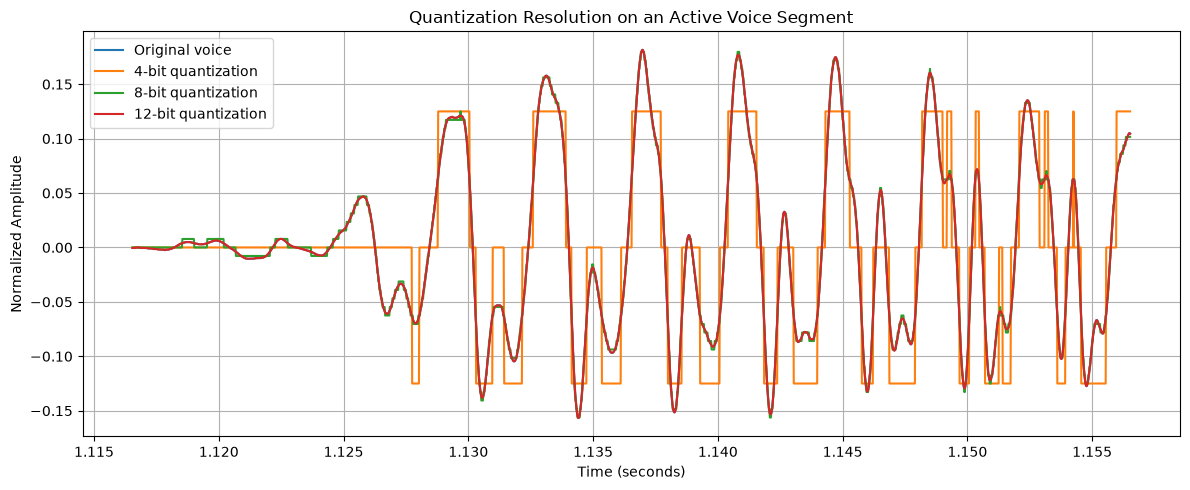

In [15]:
# ==========================================
# TASK 2.5 - CORRECTED VOICE VISUALIZATION
# ==========================================

# Find an active part of the voice recording
threshold = 0.05

active_indices = np.flatnonzero(
    np.abs(voice) > threshold
)

if len(active_indices) == 0:
    raise ValueError("No active speech detected.")

# Start shortly before the first active sample
start = max(
    active_indices[0] - int(0.01 * voice_fs),
    0
)

# Select 40 milliseconds of audio
sample_count = int(0.04 * voice_fs)
end = min(start + sample_count, len(voice))

# Extract the selected section
segment_t = np.arange(start, end) / voice_fs

plt.figure(figsize=(12, 5))

# Original recording
plt.plot(
    segment_t,
    voice[start:end],
    label="Original voice",
    linewidth=1.5
)

# Quantized recordings
for B in bits_to_test:

    plt.plot(
        segment_t,
        voice_quantized[B][start:end],
        label=f"{B}-bit quantization"
    )

plt.title("Quantization Resolution on an Active Voice Segment")
plt.xlabel("Time (seconds)")
plt.ylabel("Normalized Amplitude")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Task 2.5 – Analysis

The measured SQNR of speech is generally lower than
that of a full-scale sinusoidal signal with the same
number of quantization bits.

This is because speech signals have varying amplitudes
and contain periods of low energy and silence.

Although the recording was normalized to a peak
amplitude of 1, most speech samples do not consistently
use the entire available amplitude range.

Consequently, the quantization error can be relatively
large compared with the average speech signal power,
resulting in a lower measured SQNR.

The experiment also demonstrated that increasing the
quantization resolution from 4 bits to 8 bits and
12 bits improves the SQNR.


# WEEK 2 – ANALYSIS QUESTIONS
## Sampling, Aliasing and Quantization

---

### Question 1: Explain why a 7 Hz tone appears at 3 Hz when the sampling frequency is 10 Hz. Include a frequency-axis sketch.

**Answer:**

First, we calculate the Nyquist frequency.

The Nyquist frequency is half of the sampling frequency. It represents the highest frequency that can theoretically be represented without aliasing under ideal sampling conditions.

Given:
- Original signal frequency (f0) = 7 Hz
- Sampling frequency (fs) = 10 Hz

Calculation:

Nyquist frequency = Sampling frequency / 2

Nyquist frequency = 10 / 2

**Nyquist frequency = 5 Hz**

The original signal frequency (7 Hz) is greater than the Nyquist frequency (5 Hz). Therefore, aliasing occurs.

Next, we calculate the alias frequency:

Alias frequency = |Original frequency - Sampling frequency|

Alias frequency = |7 - 10|

**Alias frequency = 3 Hz**

#### Frequency-Axis Illustration

```text
0 Hz       3 Hz       5 Hz       7 Hz       10 Hz
 |-----------|----------|----------|-----------|
             |          |          |           |
           Alias     Nyquist   Original    Sampling
          frequency  frequency frequency   frequency
```

#### Explanation

When a continuous signal is sampled, different original frequencies can produce identical discrete-time sample values.

In this experiment, the original 7 Hz cosine signal produces the same sampled values as a 3 Hz cosine signal when the sampling frequency is 10 Hz.

Consequently, the original 7 Hz signal appears as a 3 Hz signal after sampling.

This phenomenon is called **aliasing**.

---

### Question 2: In Task 2.2, why can the aliasing heard in the naive version not be removed afterwards?

**Answer:**

Naive downsampling reduces the sampling rate by removing samples without first applying an anti-aliasing filter.

When the sampling frequency is reduced, the Nyquist frequency also decreases. Frequency components above the new Nyquist frequency can then fold into the lower-frequency range and overlap with other frequency components.

Once this overlap occurs, the original frequency components cannot generally be distinguished from the sampled data.

Therefore, the lost information cannot be recovered simply by applying a filter after downsampling.

Proper decimation prevents this problem by applying a low-pass anti-aliasing FIR filter before reducing the sampling frequency.

**Conclusion:**

Anti-aliasing filtering must be performed before downsampling to prevent unwanted frequency components from appearing as lower-frequency signals.

---

### Question 3: By how much does the Signal-to-Quantization-Noise Ratio (SQNR) change when one bit is added? Does your measurement agree?

**Answer:**

The Signal-to-Quantization-Noise Ratio (SQNR) measures the relationship between the original signal power and the power of the quantization error.

It indicates how accurately a digital system represents the original signal.

The theoretical SQNR formula for a full-scale sinusoidal signal is:

SQNR (dB) = 6.02 × B + 1.76

Where:
- SQNR = Signal-to-Quantization-Noise Ratio in decibels.
- B = Number of quantization bits.

According to this formula, adding one bit improves the theoretical SQNR by approximately:

**6.02 dB per additional bit.**

#### Experimental Verification

In our experiment, the quantization resolution was increased by two bits at each measurement interval.

The measured average improvements were approximately:

12.76 dB for every two additional bits.

Therefore:

Measured improvement per bit = 12.76 / 2

**Measured improvement = 6.38 dB per bit.**

#### Conclusion

The experimental improvement of approximately 6.38 dB per bit is close to the theoretical value of 6.02 dB per bit.

The small differences between measured and theoretical values are caused by the finite number of signal samples and the characteristics of the quantization error.

Therefore, the experiment approximately verifies the **6 dB-per-bit rule**.

---

### Question 4: A temperature sensor changes by at most 0.1 °C per second and requires a resolution of 0.01 °C over a range of 0–100 °C. Suggest a sampling rate and number of bits, and justify your answer.

**Answer:**

We are required to select a suitable sampling frequency and ADC resolution for a temperature measurement system.

#### Given Information

- Maximum temperature change = 0.1 °C per second.
- Required temperature resolution = 0.01 °C.
- Temperature measurement range = 0–100 °C.

#### Part A: Calculate the Sampling Frequency

First, calculate the maximum time interval allowed for the temperature to change by the required resolution of 0.01 °C.

Time interval = Required resolution / Maximum temperature change

Time interval = 0.01 / 0.1

**Time interval = 0.1 seconds**

The corresponding sampling frequency is:

Sampling frequency = 1 / Time interval

Sampling frequency = 1 / 0.1

**Minimum resolution-based sampling rate = 10 Hz.**

For additional sampling margin, we recommend selecting a sampling frequency of:

**Recommended sampling frequency = 20 Hz.**

At 20 Hz, the sampling interval is 0.05 seconds. Assuming the stated maximum rate of temperature change, the temperature changes by no more than 0.005 °C between consecutive samples.

#### Part B: Calculate the Number of ADC Bits

An Analog-to-Digital Converter (ADC) converts analogue sensor measurements into digital values.

The number of available quantization levels is determined by:

Number of levels = 2^B

Where B represents the ADC resolution in bits.

To achieve a resolution of 0.01 °C over a 100 °C range, the number of levels must be at least:

Required levels = Measurement range / Required resolution

Required levels = 100 / 0.01

**Required levels = 10,000**

Therefore:

2^B must be greater than or equal to 10,000.

Taking logarithms:

B must be greater than or equal to log2(10,000).

B must be greater than or equal to 13.29.

Since the ADC resolution must be a whole number of bits, we select:

**Required ADC resolution = 14 bits.**

#### Part C: Verify the Quantization Step Size

A 14-bit ADC provides:

Number of levels = 2^14

Number of levels = 16,384.

The quantization step size is:

Quantization step = Measurement range / Number of levels

Quantization step = 100 / 16,384

**Quantization step = 0.006104 °C (approximately).**

This value is smaller than the required resolution of 0.01 °C.

#### Final Recommendation

The proposed temperature measurement system should use:

- Sampling frequency: 20 Hz.
- ADC resolution: 14 bits.
- Quantization step size: Approximately 0.006104 °C.

These selections satisfy the stated resolution and measurement-range requirements under the assumptions of the calculation.

**Engineering Note:** The 10 Hz sampling estimate is based on the maximum temperature change and required measurement resolution. A formal Nyquist sampling rate would additionally require information about the temperature signal's frequency content and bandwidth.

---

## Overall Conclusion

The four experiments demonstrate important principles of digital signal processing.

1. Aliasing occurs when a signal is sampled below the required sampling frequency.
2. Anti-aliasing filters prevent unwanted frequency components from folding into the sampled signal.
3. Increasing quantization resolution improves the Signal-to-Quantization-Noise Ratio.
4. Appropriate sampling frequency and ADC resolution are important when designing digital measurement systems.


# WEEK 2 – EXPERIMENTAL OBSERVATIONS
## Sampling, Aliasing and Quantization

### Task 2.1 – Aliasing of a Sinusoid

In this experiment, a 7 Hz cosine signal was sampled using four different sampling frequencies: 10 Hz, 12 Hz, 14 Hz and 20 Hz.

The following results were obtained:

- At 10 Hz, the original 7 Hz signal appeared as 3 Hz.
- At 12 Hz, it appeared as 5 Hz.
- At 14 Hz, the signal was sampled at the Nyquist frequency of 7 Hz.
- At 20 Hz, the original 7 Hz signal was below the Nyquist frequency of 10 Hz.

The results showed that using a low sampling frequency can cause aliasing. This makes the digital signal appear to have a different frequency from the original signal.

Therefore, choosing a suitable sampling frequency is important when converting analog signals into digital signals.

---

### Task 2.2 – Hearing Aliasing

In this experiment, I used my recorded voice to investigate the effects of reducing the sampling frequency.

I compared two methods:
1. Naive downsampling, which removes samples without filtering.
2. Proper decimation, which applies an FIR low-pass filter before removing samples.

The original recording had a sampling frequency of 48,000 Hz.

The new sampling frequencies were:

- Reduction factor 2: 24,000 Hz.
- Reduction factor 4: 12,000 Hz.
- Reduction factor 8: 6,000 Hz.

The experiment showed that naive downsampling can introduce aliasing because samples are removed without first filtering unwanted high-frequency components.

Proper decimation reduces this problem by applying an anti-aliasing filter before downsampling.

At a reduction factor of 8, the new Nyquist frequency was 3,000 Hz. Therefore, frequencies above this limit needed to be reduced before downsampling.

This experiment demonstrated why anti-aliasing filters are important in digital audio processing.

---

### Task 2.3 – A Uniform Quantizer

In this experiment, I generated a 300 Hz sinusoidal signal with an amplitude of 0.99 V and sampled it at 8,000 Hz.

I then applied a 3-bit uniform quantizer over a voltage range of -1 V to +1 V.

The results were:

- Number of bits: 3.
- Number of quantization levels: 8.
- Quantization step size: 0.25 V.
- Number of samples: 80.

From the graph, I observed that the original smooth sinusoidal signal became a staircase-like signal after quantization.

This happened because the original signal amplitudes were converted into the nearest available digital levels.

The difference between the original and quantized signals represents the quantization error.

The experiment showed that using fewer quantization levels introduces errors when representing signal amplitudes digitally.

---

### Task 2.4 – Verification of the 6 dB-per-bit Rule

In this experiment, I calculated the Signal-to-Quantization-Noise Ratio (SQNR) using different quantization resolutions, from 2 bits to 16 bits.

I compared the measured SQNR values with the theoretical values using a graph.

Some of the measured results were:

- 2 bits: 9.60 dB.
- 8 bits: 48.93 dB.
- 16 bits: 98.91 dB.

The results showed that SQNR increased as the number of quantization bits increased.

The average measured improvement was approximately 6.38 dB per bit, which was close to the theoretical value of 6.02 dB per bit.

This experiment demonstrated that increasing the number of bits improves signal quality by reducing the effect of quantization noise.

---

### Task 2.5 – Quantization of My Voice

In this experiment, I used my recorded voice to investigate the effects of different quantization resolutions.

I quantized the recording using 4-bit, 8-bit and 12-bit resolutions.

My original recording had a sampling frequency of 48,000 Hz and a duration of approximately 4.85 seconds.

The results were:

| Quantization | Number of levels | Measured SQNR |
|---|---:|---:|
| 4 bits | 16 | 17.74 dB |
| 8 bits | 256 | 40.95 dB |
| 12 bits | 4,096 | 64.78 dB |

From the waveform comparison, I observed that the 4-bit signal had more noticeable amplitude steps than the 8-bit and 12-bit signals.

The 8-bit and 12-bit signals followed the original voice waveform more closely because they had more available quantization levels.

The SQNR results also increased with the number of bits.

This experiment showed that using more quantization bits improves the accuracy of digital audio representation.

---

## Overall Experimental Observation

The Week 2 experiments helped me understand how sampling and quantization affect digital signals.

I learned that insufficient sampling can cause aliasing and that anti-aliasing filters help prevent this problem.

I also observed that quantization changes the amplitude of a signal by converting it into a limited number of digital levels.

Finally, the experiments showed that increasing the number of quantization bits reduces quantization error and improves SQNR.

Overall, I gained practical understanding of how sampling frequency and quantization resolution affect digital signal quality.